# 9b. E3SM stratospheric climatology against ERA5

How does E3SM's stratosphere compare with ERA5 before any forecast is read? The model climatology is
the Reanalysis (BruteForce) 1981-2010 hindcasts at each lead (May and Nov starts, all years and
members), which is also the baseline the forecast anomalies of 9c-9i are measured from.

* Seasonal cycle of U(60°N, 10 hPa) and 10-hPa polar-cap temperature by calendar month.
* DJF zonal-mean U, model minus ERA5 (latitude-pressure).
* DJF vortex strength and its interannual variability (the spread that sets the model tercile bounds in 9c).

**Findings (as of the 2026 runs).** E3SM's vortex is about 10 m/s too weak in Dec-Jan (24 vs 33 m/s)
with no midwinter peak, and breaks down later (stronger than ERA5 in Mar-Apr); its DJF interannual
standard deviation is about 4 m/s against 10 m/s in ERA5; the 10-hPa polar cap is 4-6 K too cold and
the summer easterlies too weak.

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

### Run controls

In [2]:
NOTEBOOK = "9b_strat_model_climatology"   # outputs: rc.OUTPUT_ROOT/9b_strat_model_climatology/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX


fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.77 s, sys: 1.11 s, total: 3.88 s
Wall time: 32.8 s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

### Model stratospheric climatology against ERA5

Monthly U(60°N, 10 hPa) and 10-hPa polar-cap temperature by calendar month: ERA5 1981-2010
(mean and ±1 standard deviation of the monthly means) and the Reanalysis hindcasts at each
lead (May and Nov starts, all years and members, so the shading is the model's total spread). Right:
DJF zonal-mean U, the model at leads 1-3 of the Nov starts minus ERA5 (shading) with ERA5 contours.

The table below the figure compares the DJF vortex strength and its interannual standard deviation: E3SM's vortex is weaker (about 23 vs 29 m/s) and varies much less from winter to winter (about 4 vs 10 m/s), so the model tercile bounds in section 6 are narrow, and a few m/s of anomaly moves most members out of the middle tercile.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9b_strat_model_climatology/figures/fig_climatology_u60_t60_10hpa_djf_u_bias.png


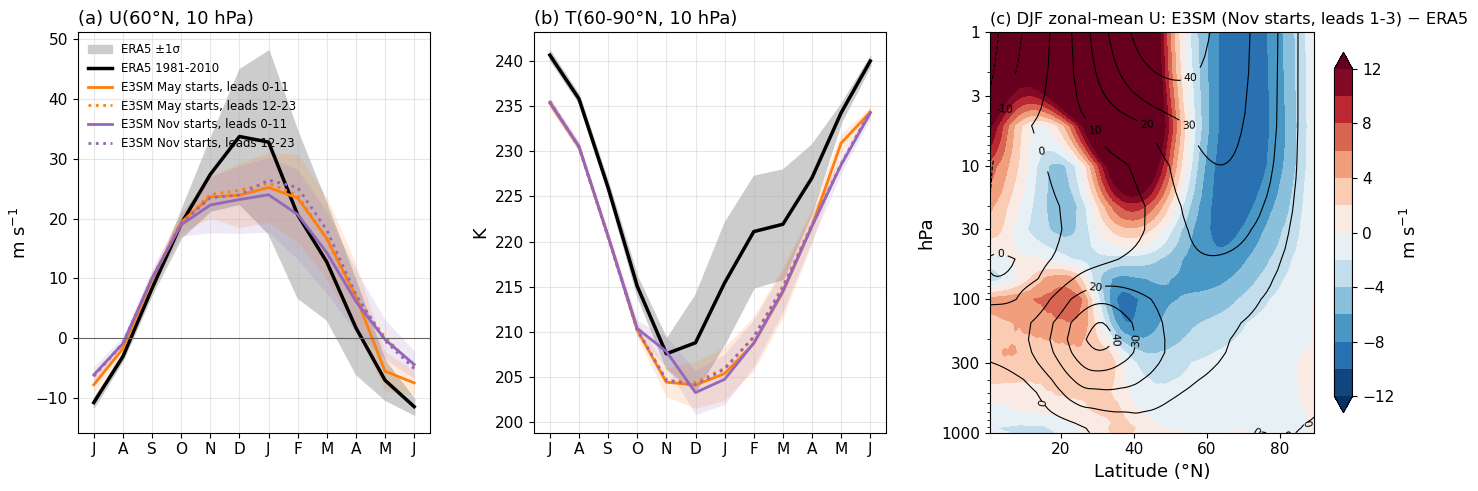

U(60N, 10 hPa) monthly climatology, m/s


,Oct,Nov,Dec,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep
ERA5,19.1,27.4,33.7,32.8,20.6,12.7,1.7,-7.1,-11.5,-10.8,-3.1,8.3
E3SM May starts (leads 0-11),19.4,23.6,23.9,25.2,23.4,16.7,7.0,-5.6,-7.5,-7.8,-1.8,9.8
E3SM Nov starts (leads 0-11),19.0,22.3,23.2,24.0,20.7,14.3,6.1,-0.2,-4.4,-6.2,-0.9,10.0


DJF U(60N, 10 hPa): mean and interannual standard deviation


,set,DJF mean (m/s),total sd,sd of yearly ensemble means,within-year member sd
0,E3SM May starts (leads 7-9),24.21,3.86,1.96,3.28
1,E3SM Nov starts (leads 1-3),22.69,4.33,2.43,3.46
2,ERA5 1981/82-2009/10,29.12,9.84,NaN,NaN


In [5]:
fig = plt.figure(figsize=(17, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15], wspace=0.28)
ref_colors = {5: "tab:orange", 11: "tab:purple"}
for k, (field, name, units) in enumerate([("U", "U(60°N, 10 hPa)", "m s$^{-1}$"), ("T", "T(60-90°N, 10 hPa)", "K")]):
    ax = fig.add_subplot(gs[k])
    band = sc.U60 if field == "U" else sc.PCAP
    e_series = sc.monthly_means(e_u60 if field == "U" else E.pct)
    e_series = e_series.sel(time=slice(f"{CLIM_YEARS[0]}-01", f"{CLIM_YEARS[1]}-12"))
    g = e_series.groupby("time.month")
    order = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
    x = np.arange(12)
    mean, std = g.mean().sel(month=order).values, g.std().sel(month=order).values
    ax.fill_between(x, mean - std, mean + std, color="0.8", label="ERA5 ±1σ")
    ax.plot(x, mean, "k-", lw=2.5, label=f"ERA5 {CLIM_YEARS[0]}-{CLIM_YEARS[1]}")
    for m, ds in ref.items():
        idx = sc.lat_mean(ds[field].sel(plev=REF_LEVEL), band)                       # (year, member, lead)
        months = sc.target_months(m)
        for half in (0, 1):                                                          # leads 0-11, 12-23
            leads = np.arange(12 * half, 12 * half + 12)
            xs = np.array([order.index(months[l]) for l in leads])
            srt = np.argsort(xs)
            mu = idx.isel(lead=leads).mean(("year", "member")).values[srt]
            sd = idx.isel(lead=leads).std(("year", "member")).values[srt]
            ls = "-" if half == 0 else ":"
            ax.plot(xs[srt], mu, ls, color=ref_colors[m], lw=2,
                    label=f"E3SM {MONTH_NAMES[m]} starts, leads {leads[0]}-{leads[-1]}")
            if half == 0:
                ax.fill_between(xs[srt], mu - sd, mu + sd, color=ref_colors[m], alpha=0.15, lw=0)
    if field == "U":
        ax.axhline(0, color="0.4", lw=0.8)
    ax.set_xticks(x, [MONTH_NAMES[m][0] for m in order])
    ax.set_title(f"({'ab'[k]}) {name}", loc="left")
    ax.set_ylabel(units)
    ax.grid(alpha=0.3)
    if k == 0:
        ax.legend(loc="upper left", fontsize=fontz * 0.65, frameon=False)

ax = fig.add_subplot(gs[2])
nov = ref[11]["U"].isel(lead=[1, 2, 3]).mean(("year", "member", "lead"))
obs_djf = e_month_clim_m["U"].sel(month=[12, 1, 2]).mean("month")
diff = (nov - obs_djf).sel(lat=slice(0, 90))
levels = np.arange(-12, 13, 2)
cf = ax.contourf(diff["lat"], diff["plev"], diff, levels=levels, cmap="RdBu_r", extend="both")
cs = ax.contour(obs_djf["lat"].sel(lat=slice(0, 90)), obs_djf["plev"], obs_djf.sel(lat=slice(0, 90)),
                levels=np.arange(-40, 81, 10), colors="k", linewidths=0.8)
ax.clabel(cs, fmt="%d", fontsize=fontz * 0.6)
ax.set_yscale("log")
ax.set_ylim(1000, 1)
ax.set_yticks([1000, 300, 100, 30, 10, 3, 1], ["1000", "300", "100", "30", "10", "3", "1"])
ax.set_xlabel("Latitude (°N)")
ax.set_ylabel("hPa")
ax.set_title("(c) DJF zonal-mean U: E3SM (Nov starts, leads 1-3) − ERA5", loc="left", fontsize=fontz * 0.9)
fig.colorbar(cf, ax=ax, label="m s$^{-1}$", shrink=0.9)
save(fig, "climatology", "u60_t60_10hPa", "djf_u_bias")
plt.show()

clim_table = pd.DataFrame({
    "ERA5": e_u60_month.sel(time=slice(f"{CLIM_YEARS[0]}-01", f"{CLIM_YEARS[1]}-12")).groupby("time.month").mean().to_series(),
    **{f"E3SM {MONTH_NAMES[m]} starts (leads 0-11)": pd.Series(
        sc.lat_mean(ds["U"].sel(plev=REF_LEVEL), sc.U60).isel(lead=slice(0, 12)).mean(("year", "member")).values,
        index=sc.target_months(m)[:12]) for m, ds in ref.items()},
}).loc[[10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]].round(1)
clim_table.index = [MONTH_NAMES[m] for m in clim_table.index]
print(f"U(60N, {REF_LEVEL:g} hPa) monthly climatology, m/s")
display(clim_table.T)

# DJF vortex strength and its interannual variability: the model spread sets the width of its tercile bounds (section 6)
W_DJF = xr.DataArray([31.0, 31.0, 28.0], dims="lead")
var_rows = []
for m, ds in ref.items():
    leads = [(12 - m) % 12, (12 - m) % 12 + 1, (12 - m) % 12 + 2]
    u = sc.lat_mean(ds["U"].sel(plev=REF_LEVEL), sc.U60).isel(lead=leads)
    djf = (u * W_DJF.assign_coords(lead=u["lead"])).sum("lead") / 90.0
    var_rows.append({"set": f"E3SM {MONTH_NAMES[m]} starts (leads {leads[0]}-{leads[-1]})", "DJF mean (m/s)": float(djf.mean()),
                     "total sd": float(djf.std()), "sd of yearly ensemble means": float(djf.mean("member").std("year")),
                     "within-year member sd": float(djf.std("member").mean())})
e_d = [float((e_u60_month.sel(time=[np.datetime64(f"{y}-12-15"), np.datetime64(f"{y + 1}-01-15"), np.datetime64(f"{y + 1}-02-15")])
              * np.array([31.0, 31.0, 28.0])).sum() / 90.0) for y in range(CLIM_YEARS[0], CLIM_YEARS[1])]
var_rows.append({"set": f"ERA5 {CLIM_YEARS[0]}/{str(CLIM_YEARS[0] + 1)[2:]}-{CLIM_YEARS[1] - 1}/{str(CLIM_YEARS[1])[2:]}",
                 "DJF mean (m/s)": np.mean(e_d), "total sd": np.std(e_d, ddof=1)})
print(f"DJF U(60N, {REF_LEVEL:g} hPa): mean and interannual standard deviation")
display(pd.DataFrame(var_rows).round(2))